# Model Development and Optimization for Motor Imagery EEG

## Research Motivation

Previous experiments highlighted the influence of channel selection, temporal segmentation, and model architecture on cross-subject EEG classification.

This notebook systematically investigates classical ML and deep learning approaches under a common subject-aware evaluation framework.

## Objectives

- Compare CSP/FBCSP, EEGNet, DeepConvNet, and ATCNet.
- Investigate channel configurations and temporal windows.
- Examine training stability and subject-level variability.
- Perform leakage-aware model selection and exploratory evaluation.
- Identify candidate configurations for independent testing.

## Evaluation Protocol

**Development cohort:** S001–S020 (20 subjects, 60 recordings).

**Task:** Binary classification of left-hand (T1) versus right-hand (T2) motor imagery.

**Primary metric:** Balanced Accuracy.

**Secondary metric:** Macro-F1.

Model configuration selection uses subject-aware validation. LOSO results on the development cohort are treated as exploratory, with an independent subject-level holdout reserved for Notebook 11.

## References

- [Chang et al. (2026), Evaluating Validation Strategies in Motor Imagery EEG](https://doi.org/10.3390/brainsci16080873)
- [Tuimebay et al. (2026), Optimization of Low-Channel EEG Configurations](https://doi.org/10.3390/a19070588)

## 1. Experimental Configuration

We define four sensorimotor channel configurations and the initial CSP/FBCSP search space.

Channel selection and temporal window length will also be investigated separately for each neural architecture.

The initial preprocessing window is 0–2 s; alternative windows will be evaluated in subsequent experiments.

In [1]:
from itertools import product
import pandas as pd

channel_options = {"3 channels": ["C3", "Cz", "C4"],
                   "5 channels": ["C3", "C1", "Cz", "C2", "C4"],
                   "6 channels": ["C3", "Cz", "C4", "CP3", "CPz", "CP4"],
                   "15 channels": ["FC3", "FC1", "FCz", "FC2", "FC4",
                                   "C3", "C1", "Cz", "C2", "C4",
                                   "CP3", "CP1", "CPz", "CP2", "CP4"]}
feature_methods = ["CSP", "FBCSP"]
classifiers = ["LDA", "SVM"]
task_window = (0.0, 2.0)

experiment_configs = pd.DataFrame([{"Channels": channel_name,
                                    "Feature Extraction": feature_method,
                                    "Classifier": classifier,
                                    "Window": "0–2 s"}
    for channel_name, feature_method, classifier in product(channel_options, feature_methods, classifiers)])

display(experiment_configs)

print("Total configurations:", len(experiment_configs))

,Channels,Feature Extraction,Classifier,Window
0,3 channels,CSP,LDA,0–2 s
1,3 channels,CSP,SVM,0–2 s
2,3 channels,FBCSP,LDA,0–2 s
3,3 channels,FBCSP,SVM,0–2 s
4,5 channels,CSP,LDA,0–2 s
5,5 channels,CSP,SVM,0–2 s
6,5 channels,FBCSP,LDA,0–2 s
7,5 channels,FBCSP,SVM,0–2 s
8,6 channels,CSP,LDA,0–2 s
9,6 channels,CSP,SVM,0–2 s


Total configurations: 16


**Conclusion:** The initial classical ML search space contains 16 combinations of channel sets, feature extraction methods, and classifiers. The task window is fixed at 0–2 s for the baseline experiments. Neural architectures will be evaluated separately using model-specific configurations.

### Development Cohort

We use 20 subjects (S001–S020) from the PhysioNet EEG Motor Movement/Imagery dataset, with three motor imagery recordings per subject (R04, R08, R12).

These subjects form the development cohort for model exploration and configuration selection. Independent evaluation will use previously unseen subjects.

In [2]:
development_subjects = [f"S{i:03d}" for i in range(1, 21)]

assert len(development_subjects) == 20
assert len(set(development_subjects)) == 20

print("Development subjects:", len(development_subjects))
print("Subject range:", development_subjects[0], "-", development_subjects[-1])
print("Recordings:", len(development_subjects) * 3)

Development subjects: 20
Subject range: S001 - S020
Recordings: 60


### EEG Data Availability

We verify that all 60 EDF recordings are available for the 20 development subjects.

This check ensures that the joint model comparison will use a complete and consistent dataset before preprocessing.

In [3]:
from pathlib import Path

data_dir = Path("../data/raw")
runs = ["04", "08", "12"]

recording_paths = [data_dir / f"{subject}R{run}.edf"
                   for subject in development_subjects for run in runs]

missing_files = [path.name for path in recording_paths if not path.is_file()]

print("Expected recordings:", len(recording_paths))
print("Available recordings:", len(recording_paths) - len(missing_files))
print("Missing recordings:", missing_files)

assert not missing_files, "Some EEG recordings are missing."

Expected recordings: 60
Available recordings: 60
Missing recordings: []


## 2. Data Preparation and Validation

We validate the shared EEG preprocessing pipeline before preparing the full development dataset.

The initial test uses S001R04, 15 sensorimotor channels, an 8–30 Hz band-pass filter, and a 0–2 s task window.

We verify tensor dimensions, class labels, and signal consistency with Notebook 09.

In [4]:
import sys
import numpy as np
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.preprocessing import load_eeg_recording

data_dir = project_root / "data/raw"
bands_test = {"8–30 Hz": (8, 30)}

X_test, y_test = load_eeg_recording(data_dir / "S001R04.edf", channel_options["15 channels"], bands_test,
                                    tmin=task_window[0], tmax=task_window[1])

print("EEG shape:", X_test.shape)
print("Labels shape:", y_test.shape)
print("Class counts:", dict(zip(*np.unique(y_test, return_counts=True))))
print("Finite values:", np.isfinite(X_test).all())

EEG shape: (15, 1, 15, 321)
Labels shape: (15,)
Class counts: {np.int64(0): np.int64(8), np.int64(1): np.int64(7)}
Finite values: True


### Preprocessing Consistency Check

We compare the refactored preprocessing output with the reference implementation from Notebook 09 to verify signal and label consistency before processing the full dataset.

In [5]:
import mne

raw_check = mne.io.read_raw_edf(data_dir / "S001R04.edf", preload=True, verbose=False)
raw_check.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
raw_check.filter(l_freq=8.0, h_freq=30.0, picks="eeg", verbose=False)

events_check, event_id_check = mne.events_from_annotations(raw_check, verbose=False)

channel_lookup = {ch.rstrip(".").upper(): ch for ch in raw_check.ch_names}
selected_channels = [channel_lookup[ch.upper()] for ch in channel_options["15 channels"]]

epochs_check = mne.Epochs(raw_check, events_check,
                          event_id={"T1": event_id_check["T1"], "T2": event_id_check["T2"]},
                          tmin=task_window[0], tmax=task_window[1], picks=selected_channels,
                          baseline=None, preload=True, verbose=False)

X_reference = epochs_check.get_data(picks=selected_channels)
y_reference = np.where(epochs_check.events[:, -1] == event_id_check["T1"], 0, 1)

max_difference = np.max(np.abs(X_test[:, 0, :, :] - X_reference))

print("Reference shape:", X_reference.shape)
print("Maximum signal difference (V):", f"{max_difference:.3e}")
print("Signals match:", np.allclose(X_test[:, 0, :, :], X_reference, rtol=1e-5, atol=1e-12))
print("Labels match:", np.array_equal(y_test, y_reference))

Reference shape: (15, 15, 321)
Maximum signal difference (V): 0.000e+00
Signals match: True
Labels match: True


**Conclusion:** The refactored preprocessing function reproduces the reference EEG signals and class labels for the tested recording and frequency band. We can proceed to multi-band preprocessing validation before preparing the full development dataset.

### Filter Bank Validation

We validate the four frequency bands used for FBCSP, checking tensor dimensions, label consistency, and signal power before processing all recordings.

In [6]:
filter_bands = {"8–12 Hz": (8, 12),
                "12–16 Hz": (12, 16),
                "16–22 Hz": (16, 22),
                "22–30 Hz": (22, 30)}

X_fb_test, y_fb_test = load_eeg_recording(data_dir / "S001R04.edf", channel_options["15 channels"], filter_bands,
                                         tmin=task_window[0], tmax=task_window[1])

band_power = np.mean(X_fb_test ** 2, axis=(0, 2, 3))

print("Filter Bank shape:", X_fb_test.shape)
print("Labels match:", np.array_equal(y_test, y_fb_test))
print("Finite values:", np.isfinite(X_fb_test).all())

print("\nMean signal power by frequency band (V²):")
for band_name, power in zip(filter_bands, band_power):
    print(f"{band_name}: {power:.3e}")

assert X_fb_test.shape == (15, 4, 15, 321)
assert np.array_equal(y_test, y_fb_test)
assert np.isfinite(X_fb_test).all()

Filter Bank shape: (15, 4, 15, 321)
Labels match: True
Finite values: True

Mean signal power by frequency band (V²):
8–12 Hz: 4.063e-11
12–16 Hz: 3.591e-11
16–22 Hz: 2.811e-11
22–30 Hz: 2.335e-11


**Conclusion:** The four-band preprocessing produces valid EEG tensors with consistent class labels. Mean signal power decreases across higher frequency bands, while the discriminative value of individual bands remains to be evaluated.

### Full Development Dataset

The preprocessing pipeline has been validated for single-band CSP and four-band FBCSP.

We now process all 60 recordings, preserving consistent class labels, subject identifiers, and 15 sensorimotor channels for subsequent model-specific experiments.

In [7]:
X_csp_list, X_fbcsp_list = [], []
y_list, groups_list = [], []

for subject in development_subjects:
    for run in runs:
        file_path = data_dir / f"{subject}R{run}.edf"

        X_csp_run, y_csp_run = load_eeg_recording(file_path, channel_options["15 channels"], bands_test,
                                                  tmin=task_window[0], tmax=task_window[1])
        X_fbcsp_run, y_fbcsp_run = load_eeg_recording(file_path, channel_options["15 channels"],filter_bands, 
                                                      tmin=task_window[0], tmax=task_window[1])

        assert np.array_equal(y_csp_run, y_fbcsp_run), f"Label mismatch: {file_path.name}"
        assert X_csp_run.shape[0] == X_fbcsp_run.shape[0], f"Epoch mismatch: {file_path.name}"

        X_csp_list.append(X_csp_run[:, 0, :, :])
        X_fbcsp_list.append(X_fbcsp_run)
        y_list.append(y_csp_run)
        groups_list.extend([subject] * len(y_csp_run))

X_csp = np.concatenate(X_csp_list, axis=0)
X_fbcsp = np.concatenate(X_fbcsp_list, axis=0)
y = np.concatenate(y_list)
groups = np.array(groups_list)

print("CSP shape:", X_csp.shape)
print("FBCSP shape:", X_fbcsp.shape)
print("Labels shape:", y.shape)
print("Subjects:", len(np.unique(groups)))
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))
print("Finite values:", np.isfinite(X_csp).all() and np.isfinite(X_fbcsp).all())

assert len(X_csp) == len(X_fbcsp) == len(y) == len(groups)
assert len(np.unique(groups)) == 20
assert np.isfinite(X_csp).all() and np.isfinite(X_fbcsp).all()

CSP shape: (900, 15, 321)
FBCSP shape: (900, 4, 15, 321)
Labels shape: (900,)
Subjects: 20
Class counts: {np.int64(0): np.int64(455), np.int64(1): np.int64(445)}
Finite values: True


**Conclusion:** The development dataset contains 900 motor imagery epochs from 20 subjects, with aligned CSP/FBCSP representations, valid signals, and consistent labels. The data are ready for subject-aware evaluation.

## 3. Subject-Aware Validation Protocol

We use Leave-One-Subject-Out (LOSO) for outer evaluation and 4-fold GroupKFold for inner model selection.

Each outer fold holds out one subject, while inner folds preserve subject independence during configuration selection.

We verify group separation and class distributions before running the experiments.

In [8]:
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold

outer_cv = LeaveOneGroupOut()
inner_cv = GroupKFold(n_splits=4)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X_csp, y, groups), start=1):
    train_subjects = set(groups[train_idx])
    test_subjects = set(groups[test_idx])

    assert train_subjects.isdisjoint(test_subjects)

    for inner_train, inner_val in inner_cv.split(X_csp[train_idx], y[train_idx], groups[train_idx]):
        assert set(groups[train_idx][inner_train]).isdisjoint(set(groups[train_idx][inner_val]))

    fold_results.append({"Fold": fold,
                         "Train Subjects": len(train_subjects),
                         "Test Subjects": len(test_subjects),
                         "Train Epochs": len(train_idx),
                         "Test Epochs": len(test_idx),
                         "Test T1": int(np.sum(y[test_idx] == 0)),
                         "Test T2": int(np.sum(y[test_idx] == 1))})

fold_df = pd.DataFrame(fold_results)

display(fold_df.head())
print("Total folds:", len(fold_df))
print("Total test epochs:", fold_df["Test Epochs"].sum())
print("Total test T1:", fold_df["Test T1"].sum())
print("Total test T2:", fold_df["Test T2"].sum())

assert len(fold_df) == 20
assert (fold_df["Train Subjects"] == 19).all()
assert (fold_df["Test Subjects"] == 1).all()
assert fold_df["Test Epochs"].sum() == len(y)

,Fold,Train Subjects,Test Subjects,Train Epochs,Test Epochs,Test T1,Test T2
0,1,19,1,855,45,23,22
1,2,19,1,855,45,23,22
2,3,19,1,855,45,23,22
3,4,19,1,855,45,23,22
4,5,19,1,855,45,21,24


Total folds: 20
Total test epochs: 900
Total test T1: 455
Total test T2: 445


**Conclusion:** The LOSO protocol produces 20 outer folds with no subject overlap between training and test sets. Inner GroupKFold preserves subject separation, and all 900 epochs are covered exactly once across outer test folds.

## 4. Classical ML: CSP and FBCSP

### 4.1 Feature Extraction Validation

We first verify that the FilterBankCSP transformer extracts valid features from the four frequency bands.

Each band produces three CSP features, resulting in 12 features per epoch.

In [9]:
from src.features import FilterBankCSP

train_mask = np.isin(groups, ["S001", "S002"])
test_mask = groups == "S003"

fbcsp_check = FilterBankCSP(n_components=3)
fbcsp_check.fit(X_fbcsp[train_mask], y[train_mask])

features_check = fbcsp_check.transform(X_fbcsp[test_mask])

print("Training epochs:", train_mask.sum())
print("Test epochs:", test_mask.sum())
print("Extracted features shape:", features_check.shape)
print("CSP models:", len(fbcsp_check.csps_))
print("Finite values:", np.isfinite(features_check).all())

assert features_check.shape == (45, 12)
assert len(fbcsp_check.csps_) == 4
assert np.isfinite(features_check).all()

Training epochs: 90
Test epochs: 45
Extracted features shape: (45, 12)
CSP models: 4
Finite values: True


**Conclusion:** FilterBankCSP successfully extracts 12 valid features per epoch using four independently fitted CSP models. The transformer is ready for subject-aware model evaluation.

### 4.2 Inner Cross-Validation: Configuration Selection

We evaluate 16 classical ML configurations using four-fold GroupKFold within the first outer LOSO training set.

Configurations differ in channel selection (3, 5, 6, 15), feature extraction (CSP/FBCSP), and classifier (LDA/SVM).

Each configuration is ranked by mean subject-level balanced accuracy. The held-out subject S001 is excluded from selection.

In [10]:
from src.models import build_model
from itertools import product
from sklearn.metrics import balanced_accuracy_score

outer_train_idx, outer_test_idx = next(outer_cv.split(X_csp, y, groups))
inner_results = []

for channel_name, feature_method, classifier in product(channel_options, feature_methods, classifiers):
    selected_channels = channel_options[channel_name]
    channel_indices = [channel_options["15 channels"].index(ch) for ch in selected_channels]

    X_data = X_csp[:, channel_indices, :] if feature_method == "CSP" else X_fbcsp[:, :, channel_indices, :]
    subject_scores = []

    for inner_train, inner_val in inner_cv.split(X_data[outer_train_idx], y[outer_train_idx], groups[outer_train_idx]):
        train_idx = outer_train_idx[inner_train]
        val_idx = outer_train_idx[inner_val]

        model = build_model(feature_method, classifier)

        with mne.use_log_level("WARNING"):
            model.fit(X_data[train_idx], y[train_idx])
            y_pred = model.predict(X_data[val_idx])

        for subject in np.unique(groups[val_idx]):
            subject_mask = groups[val_idx] == subject
            score = balanced_accuracy_score(y[val_idx][subject_mask], y_pred[subject_mask])
            subject_scores.append(score)

    assert len(subject_scores) == 19

    inner_results.append({"Channels": channel_name,
                          "Features": feature_method,
                          "Classifier": classifier,
                          "Balanced Accuracy": np.mean(subject_scores),
                          "Std": np.std(subject_scores)})

inner_results_df = pd.DataFrame(inner_results).sort_values("Balanced Accuracy", ascending=False)

display(inner_results_df.round(3))
print("Evaluated configurations:", len(inner_results_df))
print("Outer test subject:", np.unique(groups[outer_test_idx]))

,Channels,Features,Classifier,Balanced Accuracy,Std
8,6 channels,CSP,LDA,0.611,0.113
11,6 channels,FBCSP,SVM,0.605,0.107
6,5 channels,FBCSP,LDA,0.602,0.086
10,6 channels,FBCSP,LDA,0.598,0.123
3,3 channels,FBCSP,SVM,0.598,0.104
1,3 channels,CSP,SVM,0.594,0.122
0,3 channels,CSP,LDA,0.593,0.104
9,6 channels,CSP,SVM,0.588,0.105
2,3 channels,FBCSP,LDA,0.587,0.095
7,5 channels,FBCSP,SVM,0.585,0.098


Evaluated configurations: 16
Outer test subject: ['S001']


**Conclusion:** Six-channel CSP + LDA achieved the highest inner-CV balanced accuracy (0.611), followed closely by six-channel FBCSP + SVM (0.605). The small differences and substantial subject-level variability do not establish a consistently superior configuration. The selected model will now be evaluated on the held-out outer subject.

### 4.3 Full Nested LOSO Evaluation

We repeat configuration selection and evaluation across all 20 outer LOSO folds.

Within each fold, 16 configurations are compared using subject-aware inner cross-validation. The selected model is then refitted on the outer training subjects and evaluated on the held-out subject.

We report balanced accuracy, Macro-F1, and the selected configuration for each subject.

In [11]:
from sklearn.metrics import balanced_accuracy_score, f1_score

nested_results = []

for fold, (outer_train_idx, outer_test_idx) in enumerate(outer_cv.split(X_csp, y, groups), start=1):
    inner_splits = list(inner_cv.split(X_csp[outer_train_idx], y[outer_train_idx], groups[outer_train_idx]))
    config_scores = []

    for channel_name, feature_method, classifier in product(channel_options, feature_methods, classifiers):
        channel_indices = [channel_options["15 channels"].index(ch) for ch in channel_options[channel_name]]
        X_data = X_csp[:, channel_indices, :] if feature_method == "CSP" else X_fbcsp[:, :, channel_indices, :]
        subject_scores = []

        for inner_train, inner_val in inner_splits:
            train_idx, val_idx = outer_train_idx[inner_train], outer_train_idx[inner_val]
            model = build_model(feature_method, classifier)

            with mne.use_log_level("WARNING"):
                model.fit(X_data[train_idx], y[train_idx])
                y_pred = model.predict(X_data[val_idx])

            for subject in np.unique(groups[val_idx]):
                mask = groups[val_idx] == subject
                subject_scores.append(balanced_accuracy_score(y[val_idx][mask], y_pred[mask]))

        config_scores.append({"Channels": channel_name, "Features": feature_method,
                              "Classifier": classifier, "Inner BA": np.mean(subject_scores)})

    best_config = max(config_scores, key=lambda row: row["Inner BA"])
    channel_indices = [channel_options["15 channels"].index(ch) for ch in channel_options[best_config["Channels"]]]
    X_data = X_csp[:, channel_indices, :] if best_config["Features"] == "CSP" else X_fbcsp[:, :, channel_indices, :]
    model = build_model(best_config["Features"], best_config["Classifier"])

    with mne.use_log_level("WARNING"):
        model.fit(X_data[outer_train_idx], y[outer_train_idx])
        y_pred = model.predict(X_data[outer_test_idx])

    nested_results.append({"Subject": groups[outer_test_idx][0],
                           "Channels": best_config["Channels"],
                           "Features": best_config["Features"],
                           "Classifier": best_config["Classifier"],
                           "Inner BA": best_config["Inner BA"],
                           "Outer BA": balanced_accuracy_score(y[outer_test_idx], y_pred),
                           "Outer Macro-F1": f1_score(y[outer_test_idx], y_pred, average="macro")})

    print(f"Fold {fold:02d}/20 | {groups[outer_test_idx][0]} | Outer BA: {nested_results[-1]['Outer BA']:.3f}")

nested_results_df = pd.DataFrame(nested_results)

display(nested_results_df.round(3))
print("\nMean Nested LOSO BA:", round(nested_results_df["Outer BA"].mean(), 3))
print("Mean Nested LOSO Macro-F1:", round(nested_results_df["Outer Macro-F1"].mean(), 3))
print("Completed folds:", len(nested_results_df))

Fold 01/20 | S001 | Outer BA: 0.618
Fold 02/20 | S002 | Outer BA: 0.594
Fold 03/20 | S003 | Outer BA: 0.598
Fold 04/20 | S004 | Outer BA: 0.565
Fold 05/20 | S005 | Outer BA: 0.616
Fold 06/20 | S006 | Outer BA: 0.560
Fold 07/20 | S007 | Outer BA: 0.909
Fold 08/20 | S008 | Outer BA: 0.607
Fold 09/20 | S009 | Outer BA: 0.607
Fold 10/20 | S010 | Outer BA: 0.616
Fold 11/20 | S011 | Outer BA: 0.534
Fold 12/20 | S012 | Outer BA: 0.583
Fold 13/20 | S013 | Outer BA: 0.800
Fold 14/20 | S014 | Outer BA: 0.549
Fold 15/20 | S015 | Outer BA: 0.717
Fold 16/20 | S016 | Outer BA: 0.555
Fold 17/20 | S017 | Outer BA: 0.523
Fold 18/20 | S018 | Outer BA: 0.520
Fold 19/20 | S019 | Outer BA: 0.630
Fold 20/20 | S020 | Outer BA: 0.518


,Subject,Channels,Features,Classifier,Inner BA,Outer BA,Outer Macro-F1
0,S001,6 channels,CSP,LDA,0.611,0.618,0.603
1,S002,6 channels,FBCSP,LDA,0.620,0.594,0.564
2,S003,3 channels,FBCSP,LDA,0.611,0.598,0.595
3,S004,6 channels,FBCSP,LDA,0.616,0.565,0.459
4,S005,6 channels,CSP,LDA,0.623,0.616,0.615
5,S006,6 channels,FBCSP,LDA,0.620,0.560,0.555
6,S007,3 channels,FBCSP,LDA,0.589,0.909,0.910
7,S008,6 channels,CSP,SVM,0.615,0.607,0.564
8,S009,6 channels,CSP,LDA,0.627,0.607,0.593
9,S010,6 channels,FBCSP,SVM,0.614,0.616,0.615



Mean Nested LOSO BA: 0.611
Mean Nested LOSO Macro-F1: 0.579
Completed folds: 20


### 4.4 Model Selection Stability

Nested LOSO achieved a mean balanced accuracy of 0.611 and Macro-F1 of 0.579.

We examine the frequency of selected configurations and variability in subject-level performance to assess the stability of model selection.

,Channels,Features,Classifier,Selected Folds
3,6 channels,CSP,LDA,7
5,6 channels,FBCSP,LDA,4
6,6 channels,FBCSP,SVM,4
1,3 channels,FBCSP,LDA,2
0,3 channels,CSP,LDA,1
2,5 channels,FBCSP,LDA,1
4,6 channels,CSP,SVM,1


Mean BA: 0.611
Median BA: 0.596
Std BA: 0.097
Subjects with BA <= 0.55: 5
Subjects with BA >= 0.70: 3


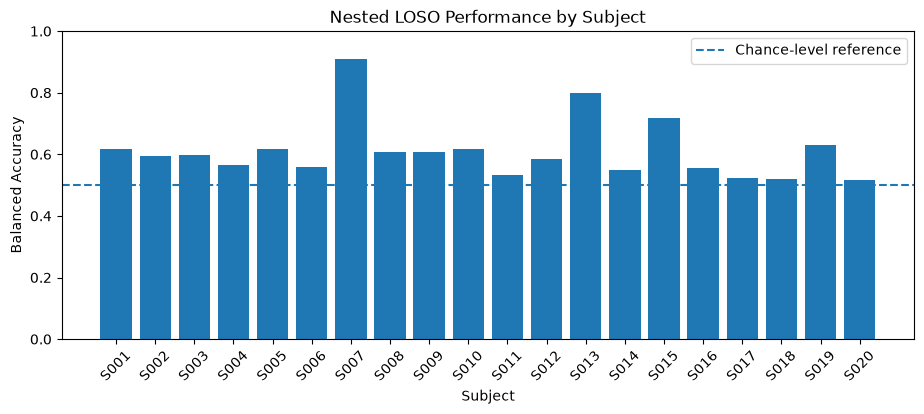

In [12]:
import matplotlib.pyplot as plt

selection_counts = nested_results_df.groupby(["Channels", "Features", "Classifier"]).size()
selection_counts = selection_counts.reset_index(name="Selected Folds")
selection_counts = selection_counts.sort_values("Selected Folds", ascending=False)

display(selection_counts)

print("Mean BA:", round(nested_results_df["Outer BA"].mean(), 3))
print("Median BA:", round(nested_results_df["Outer BA"].median(), 3))
print("Std BA:", round(nested_results_df["Outer BA"].std(), 3))
print("Subjects with BA <= 0.55:", (nested_results_df["Outer BA"] <= 0.55).sum())
print("Subjects with BA >= 0.70:", (nested_results_df["Outer BA"] >= 0.70).sum())

plt.figure(figsize=(11, 4))
plt.bar(nested_results_df["Subject"], nested_results_df["Outer BA"])
plt.axhline(0.5, linestyle="--", label="Chance-level reference")
plt.xlabel("Subject")
plt.ylabel("Balanced Accuracy")
plt.title("Nested LOSO Performance by Subject")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend()
plt.show()

**Conclusion:** Nested LOSO achieved a mean BA of 0.611 (SD = 0.097). Six-channel configurations were selected in 16 of 20 folds, but performance varied substantially across subjects. Frequent selection does not establish that six channels are universally optimal.

### 4.5 Fixed CSP Baselines

We evaluate fixed three- and six-channel CSP + LDA models using the same outer LOSO splits.

These baselines provide a reference for assessing whether adaptive configuration selection improves cross-subject classification.

In [13]:
fixed_results = []

for channel_name in ["3 channels", "6 channels"]:
    channel_indices = [channel_options["15 channels"].index(ch) for ch in channel_options[channel_name]]
    X_data = X_csp[:, channel_indices, :]

    for train_idx, test_idx in outer_cv.split(X_data, y, groups):
        model = build_model("CSP", "LDA")

        with mne.use_log_level("WARNING"):
            model.fit(X_data[train_idx], y[train_idx])
            y_pred = model.predict(X_data[test_idx])

        fixed_results.append({"Subject": groups[test_idx][0],
                              "Model": f"CSP + LDA ({channel_name})",
                              "BA": balanced_accuracy_score(y[test_idx], y_pred),
                              "Macro-F1": f1_score(y[test_idx], y_pred, average="macro")})

fixed_results_df = pd.DataFrame(fixed_results)

nested_comparison = nested_results_df[["Subject", "Outer BA", "Outer Macro-F1"]].copy()
nested_comparison["Model"] = "Nested Selection"
nested_comparison = nested_comparison.rename(columns={"Outer BA": "BA", "Outer Macro-F1": "Macro-F1"})

comparison_df = pd.concat([fixed_results_df, nested_comparison], ignore_index=True)

summary_df = comparison_df.groupby("Model")[["BA", "Macro-F1"]].agg(["mean", "std"])
display(summary_df.round(3))

subject_comparison = comparison_df.pivot(index="Subject", columns="Model", values="BA")
display(subject_comparison.round(3))

BA        Macro-F1       
                         mean    std     mean    std
Model                                               
CSP + LDA (3 channels)  0.599  0.113    0.556  0.147
CSP + LDA (6 channels)  0.624  0.114    0.591  0.142
Nested Selection        0.611  0.097    0.579  0.119

Model,CSP + LDA (3 channels),CSP + LDA (6 channels),Nested Selection
Subject,,,
S001,0.686,0.618,0.618
S002,0.523,0.568,0.594
S003,0.575,0.461,0.598
S004,0.565,0.522,0.565
S005,0.551,0.616,0.616
S006,0.521,0.458,0.560
S007,0.889,0.889,0.909
S008,0.559,0.715,0.607
S009,0.438,0.607,0.607


**Conclusion:** Six-channel CSP + LDA achieved the highest exploratory mean BA (0.624), compared with nested selection (0.611) and three-channel CSP + LDA (0.599). However, the six-channel baseline was examined after exploratory analysis, so its apparent advantage requires independent validation.

### 4.6 Paired Performance Comparison

We calculate paired subject-level differences and bootstrap confidence intervals to compare nested model selection with fixed CSP baselines.

These exploratory comparisons assess whether observed differences are consistent across subjects.

In [14]:
model_pairs = {"Nested vs CSP 6ch": ("Nested Selection", "CSP + LDA (6 channels)"),
               "Nested vs CSP 3ch": ("Nested Selection", "CSP + LDA (3 channels)"),
               "CSP 6ch vs CSP 3ch": ("CSP + LDA (6 channels)", "CSP + LDA (3 channels)")}

rng = np.random.default_rng(42)
paired_results = []

for comparison_name, (model_a, model_b) in model_pairs.items():
    differences = (subject_comparison[model_a] - subject_comparison[model_b]).to_numpy()
    bootstrap_means = rng.choice(differences, size=(10000, len(differences)), replace=True).mean(axis=1)
    ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

    paired_results.append({"Comparison": comparison_name,
                           "Mean BA Difference": differences.mean(),
                           "95% CI Lower": ci_lower,
                           "95% CI Upper": ci_upper,
                           "Improved Subjects": int((differences > 1e-10).sum()),
                           "Worse Subjects": int((differences < -1e-10).sum()),
                           "Equal Subjects": int(np.isclose(differences, 0, atol=1e-10).sum())})

paired_results_df = pd.DataFrame(paired_results)
display(paired_results_df.round(3))

,Comparison,Mean BA Difference,95% CI Lower,95% CI Upper,Improved Subjects,Worse Subjects,Equal Subjects
0,Nested vs CSP 6ch,-0.013,-0.046,0.019,7,6,7
1,Nested vs CSP 3ch,0.012,-0.015,0.039,12,6,2
2,CSP 6ch vs CSP 3ch,0.025,-0.008,0.057,13,6,1


**Conclusion:** Six-channel CSP + LDA achieved the highest mean BA (0.624), but all paired bootstrap confidence intervals included zero. Nested model selection did not demonstrate a consistent advantage over fixed baselines. Channel configuration remains an important factor, motivating systematic channel and temporal sensitivity studies across classical and deep learning models.

### 4.7 Temporal Sensitivity Analysis

Previous CSP experiments used a fixed 0–2 s window.

We now prepare 0–4 s epochs to investigate whether longer motor imagery segments improve classification. Both windows will be compared using identical subject-aware validation splits.

In [15]:
X_csp_4s_list = []
y_4s_list = []
groups_4s_list = []

for subject in development_subjects:
    for run in runs:
        file_path = data_dir / f"{subject}R{run}.edf"

        X_run, y_run = load_eeg_recording(file_path, channel_options["15 channels"], bands_test, tmin=0.0, tmax=4.0)

        X_csp_4s_list.append(X_run[:, 0, :, :])
        y_4s_list.append(y_run)
        groups_4s_list.extend([subject] * len(y_run))

X_csp_4s = np.concatenate(X_csp_4s_list, axis=0)
y_4s = np.concatenate(y_4s_list)
groups_4s = np.array(groups_4s_list)

print("0–2 s shape:", X_csp.shape)
print("0–4 s shape:", X_csp_4s.shape)
print("Labels match:", np.array_equal(y, y_4s))
print("Subjects match:", np.array_equal(groups, groups_4s))
print("Finite values:", np.isfinite(X_csp_4s).all())

assert np.array_equal(y, y_4s)
assert np.array_equal(groups, groups_4s)
assert np.isfinite(X_csp_4s).all()

0–2 s shape: (900, 15, 321)
0–4 s shape: (900, 15, 641)
Labels match: True
Subjects match: True
Finite values: True


### Temporal and Channel Sensitivity — CSP + LDA

Both temporal windows contain 900 aligned epochs with consistent labels and subject identifiers.

We compare four channel configurations across 0–2 s and 0–4 s using identical subjectб-aware inner-CV splits. Performance is measured by mean subject-level balanced accuracy.

In [16]:
window_data = {"0–2 s": X_csp, "0–4 s": X_csp_4s}

outer_train_idx, outer_test_idx = next(outer_cv.split(X_csp, y, groups))
inner_splits = list(inner_cv.split(X_csp[outer_train_idx], y[outer_train_idx], groups[outer_train_idx]))

temporal_results = []

for window_name, X_window in window_data.items():
    for channel_name, channels in channel_options.items():
        channel_indices = [channel_options["15 channels"].index(ch) for ch in channels]
        X_data = X_window[:, channel_indices, :]
        subject_scores = []

        for inner_train, inner_val in inner_splits:
            train_idx = outer_train_idx[inner_train]
            val_idx = outer_train_idx[inner_val]
            model = build_model("CSP", "LDA")

            with mne.use_log_level("WARNING"):
                model.fit(X_data[train_idx], y[train_idx])
                y_pred = model.predict(X_data[val_idx])

            for subject in np.unique(groups[val_idx]):
                mask = groups[val_idx] == subject
                subject_scores.append(balanced_accuracy_score(y[val_idx][mask], y_pred[mask]))

        temporal_results.append({"Channels": channel_name, "Window": window_name,
                                 "Mean BA": np.mean(subject_scores),
                                 "Std BA": np.std(subject_scores)})

temporal_df = pd.DataFrame(temporal_results)

display(temporal_df.round(3))

temporal_pivot = temporal_df.pivot(index="Channels", columns="Window", values="Mean BA")
temporal_pivot["Difference (4s - 2s)"] = temporal_pivot["0–4 s"] - temporal_pivot["0–2 s"]

display(temporal_pivot.round(3))

print("Evaluated configurations:", len(temporal_df))
print("Validation subjects:", len(np.unique(groups[outer_train_idx])))
print("Excluded test subject:", np.unique(groups[outer_test_idx]))

,Channels,Window,Mean BA,Std BA
0,3 channels,0–2 s,0.593,0.104
1,5 channels,0–2 s,0.579,0.087
2,6 channels,0–2 s,0.611,0.113
3,15 channels,0–2 s,0.584,0.097
4,3 channels,0–4 s,0.588,0.122
5,5 channels,0–4 s,0.549,0.081
6,6 channels,0–4 s,0.562,0.091
7,15 channels,0–4 s,0.549,0.083


Window,0–2 s,0–4 s,Difference (4s - 2s)
Channels,,,
15 channels,0.584,0.549,-0.035
3 channels,0.593,0.588,-0.005
5 channels,0.579,0.549,-0.031
6 channels,0.611,0.562,-0.049


Evaluated configurations: 8
Validation subjects: 19
Excluded test subject: ['S001']


**Conclusion:** The 0–2 s window outperformed 0–4 s across all four channel configurations. Six-channel CSP + LDA achieved the highest inner-CV balanced accuracy (0.611), while extending the window reduced performance to 0.562. These findings support using 0–2 s as the preferred CSP configuration for further investigation, although independent validation is still required.

## 5. Deep Learning Models

### 5.1 Environment Validation

Before evaluating neural architectures, we verify that PyTorch and Braindecode are available in the project environment.

The following experiments will compare EEGNet, DeepConvNet, and ATCNet using subject-aware validation.

In [17]:
import importlib.util

libraries = ["torch", "braindecode"]

for library in libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if available else 'Not installed'}")

torch: Installed
braindecode: Installed


### 5.2 EEGNet: Channel and Temporal Sensitivity

CSP experiments favored six channels and a 0–2 s window, but these settings may not be optimal for EEGNet.

We prepare eight EEGNet configurations combining four channel sets with two temporal windows. Signals are converted from volts to microvolts for neural network training.

In [18]:
eegnet_configs = {}

window_data = {"0–2 s": X_csp, "0–4 s": X_csp_4s}

for window_name, X_window in window_data.items():
    for channel_name, channels in channel_options.items():
        channel_indices = [channel_options["15 channels"].index(ch) for ch in channels]
        X_data = (X_window[:, channel_indices, :] * 1e6).astype(np.float32)

        eegnet_configs[(channel_name, window_name)] = X_data

        print(f"{channel_name}, {window_name}: {X_data.shape}")

assert len(eegnet_configs) == 8
assert all(np.isfinite(X_data).all() for X_data in eegnet_configs.values())

3 channels, 0–2 s: (900, 3, 321)
5 channels, 0–2 s: (900, 5, 321)
6 channels, 0–2 s: (900, 6, 321)
15 channels, 0–2 s: (900, 15, 321)
3 channels, 0–4 s: (900, 3, 641)
5 channels, 0–4 s: (900, 5, 641)
6 channels, 0–4 s: (900, 6, 641)
15 channels, 0–4 s: (900, 15, 641)


### Subject-Aware Configuration Selection

All eight EEGNet configurations have valid input dimensions.

We separate training, early stopping, and configuration scoring by subject to avoid using the same validation data for both checkpoint selection and configuration ranking.

In [19]:
outer_train_idx, outer_test_idx = next(outer_cv.split(X_csp, y, groups))

inner_train, inner_score = next(inner_cv.split(
    X_csp[outer_train_idx], y[outer_train_idx], groups[outer_train_idx]))

inner_train_idx = outer_train_idx[inner_train]
score_idx = outer_train_idx[inner_score]

stop_cv = GroupKFold(n_splits=4)
fit_local, stop_local = next(stop_cv.split(X_csp[inner_train_idx], y[inner_train_idx], groups[inner_train_idx]))

fit_idx = inner_train_idx[fit_local]
stop_idx = inner_train_idx[stop_local]

subject_sets = [set(groups[idx]) for idx in [fit_idx, stop_idx, score_idx, outer_test_idx]]

assert all(subject_sets[i].isdisjoint(subject_sets[j])
           for i in range(4) for j in range(i + 1, 4))

print("Training subjects:", len(subject_sets[0]))
print("Early stopping subjects:", len(subject_sets[1]))
print("Configuration scoring subjects:", len(subject_sets[2]))
print("Excluded outer subject:", np.unique(groups[outer_test_idx]))

Training subjects: 10
Early stopping subjects: 4
Configuration scoring subjects: 5
Excluded outer subject: ['S001']


### EEGNet Configuration Evaluation

The subject-aware split separates training, early stopping, and configuration scoring.

We validate the reusable evaluation function on one EEGNet configuration and one inner fold before running the full channel and temporal sensitivity analysis.

In [20]:
import importlib
import src.evaluation as evaluation

importlib.reload(evaluation)

eegnet_check_df = evaluation.evaluate_deep_config(
    eegnet_configs[("6 channels", "0–2 s")], y, groups,
    outer_train_idx, architecture="EEGNet", max_folds=1)

display(eegnet_check_df.round(3))

print("Evaluated subjects:", eegnet_check_df["Subject"].nunique())
print("Mean BA:", round(eegnet_check_df["BA"].mean(), 3))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/eegpt.py:497: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/eegpt.py:1452: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = make_standard_montage("standard_1020")


,Fold,Subject,BA,Macro-F1,Best Epoch
0,1,S004,0.714,0.706,20
1,1,S008,0.587,0.497,20
2,1,S012,0.542,0.405,20
3,1,S016,0.606,0.575,20
4,1,S020,0.501,0.375,20


Evaluated subjects: 5
Mean BA: 0.59


**Conclusion:** The evaluation function successfully assessed EEGNet on five independent configuration-scoring subjects. The first fold achieved a mean BA of 0.590, with best checkpoint at epoch 20. The procedure is ready for systematic channel and temporal sensitivity analysis.

### EEGNet Channel and Temporal Sensitivity Analysis

The subject-aware evaluation function has been validated on one configuration.

We now evaluate eight combinations of channel configurations and temporal windows using four inner folds. Each fold separates training, early stopping, and configuration scoring subjects.

Configurations are compared by mean subject-level balanced accuracy.

In [21]:
eegnet_sensitivity_results = []

for (channel_name, window_name), X_data in eegnet_configs.items():
    results_df = evaluation.evaluate_deep_config(
        X_data, y, groups, outer_train_idx, architecture="EEGNet", max_folds=4)

    eegnet_sensitivity_results.append({"Channels": channel_name,
                                       "Window": window_name,
                                       "Mean BA": results_df["BA"].mean(),
                                       "Std BA": results_df["BA"].std(),
                                       "Macro-F1": results_df["Macro-F1"].mean(),
                                       "Mean Best Epoch": results_df.groupby("Fold")["Best Epoch"].first().mean()})

    print(f"{channel_name}, {window_name} | BA: {results_df['BA'].mean():.3f} | F1: {results_df['Macro-F1'].mean():.3f}")

eegnet_sensitivity_df = pd.DataFrame(eegnet_sensitivity_results)

display(eegnet_sensitivity_df.round(3))

eegnet_pivot = eegnet_sensitivity_df.pivot(index="Channels", columns="Window", values="Mean BA")
eegnet_pivot["Difference (4s - 2s)"] = eegnet_pivot["0–4 s"] - eegnet_pivot["0–2 s"]

display(eegnet_pivot.round(3))

print("Evaluated configurations:", len(eegnet_sensitivity_df))

3 channels, 0–2 s | BA: 0.556 | F1: 0.508
5 channels, 0–2 s | BA: 0.570 | F1: 0.515
6 channels, 0–2 s | BA: 0.579 | F1: 0.512
15 channels, 0–2 s | BA: 0.564 | F1: 0.541
3 channels, 0–4 s | BA: 0.528 | F1: 0.481
5 channels, 0–4 s | BA: 0.526 | F1: 0.448
6 channels, 0–4 s | BA: 0.521 | F1: 0.470
15 channels, 0–4 s | BA: 0.523 | F1: 0.479


,Channels,Window,Mean BA,Std BA,Macro-F1,Mean Best Epoch
0,3 channels,0–2 s,0.556,0.076,0.508,18.25
1,5 channels,0–2 s,0.570,0.091,0.515,24.25
2,6 channels,0–2 s,0.579,0.106,0.512,20.50
3,15 channels,0–2 s,0.564,0.111,0.541,24.75
4,3 channels,0–4 s,0.528,0.072,0.481,16.50
5,5 channels,0–4 s,0.526,0.070,0.448,7.75
6,6 channels,0–4 s,0.521,0.073,0.470,6.75
7,15 channels,0–4 s,0.523,0.062,0.479,9.75


Window,0–2 s,0–4 s,Difference (4s - 2s)
Channels,,,
15 channels,0.564,0.523,-0.041
3 channels,0.556,0.528,-0.028
5 channels,0.570,0.526,-0.044
6 channels,0.579,0.521,-0.057


Evaluated configurations: 8


**Conclusion:** The 0–2 s window outperformed 0–4 s across all EEGNet channel configurations. Six channels achieved the highest mean BA (0.579), while 15 channels achieved the highest Macro-F1 (0.541). These findings support six channels and 0–2 s as the primary EEGNet candidate, although performance differences between channel configurations were small.

### 5.3 EEGNet: Baseline Architecture and Training Diagnostics

Channel and temporal sensitivity analysis identified six channels and a 0–2 s window as the leading EEGNet configuration by balanced accuracy.

We validate this architecture and inspect its training behavior using subject-independent training and validation groups.

The previously completed full LOSO experiment will be retained as an exploratory fixed-configuration baseline.

**Reference:** [Lawhern et al. (2018), EEGNet](https://doi.org/10.1088/1741-2552/aace8c).

In [22]:
import torch
import braindecode
from braindecode.models import EEGNet

torch.manual_seed(42)

X_eegnet = eegnet_configs[("6 channels", "0–2 s")]

eegnet_model = EEGNet(n_chans=X_eegnet.shape[1], n_outputs=2,
                      n_times=X_eegnet.shape[-1], sfreq=160)

eegnet_model.eval()

with torch.no_grad():
    output = eegnet_model(torch.from_numpy(X_eegnet[:8]))

print("PyTorch version:", torch.__version__)
print("Braindecode version:", braindecode.__version__)
print("EEG shape:", X_eegnet.shape)
print("Model output:", output.shape)
print("Trainable parameters:", sum(p.numel() for p in eegnet_model.parameters() if p.requires_grad))

assert output.shape == (8, 2)
assert torch.isfinite(output).all()

PyTorch version: 2.14.1
Braindecode version: 1.8.1
EEG shape: (900, 6, 321)
Model output: torch.Size([8, 2])
Trainable parameters: 1522


**Conclusion:** EEGNet successfully processed the six-channel EEG input and produced two class logits per epoch. The architecture contains 1,522 trainable parameters and is ready for subject-aware training.

#### EEGNet Training Diagnostics

We train the fixed six-channel EEGNet using subject-aware training and validation splits, with S001 excluded.

The shared `train_model()` function applies early stopping based on validation loss. We inspect learning curves and subject-level validation performance to identify potential generalization issues.

In [23]:
import importlib
import src.training as training

importlib.reload(training)

outer_train_idx, outer_test_idx = next(outer_cv.split(X_eegnet, y, groups))
inner_train, inner_val = next(inner_cv.split(
    X_eegnet[outer_train_idx], y[outer_train_idx], groups[outer_train_idx]))

train_idx = outer_train_idx[inner_train]
val_idx = outer_train_idx[inner_val]

assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
assert set(groups[outer_test_idx]).isdisjoint(set(groups[train_idx]))
assert set(groups[outer_test_idx]).isdisjoint(set(groups[val_idx]))

eegnet_model, history, best_epoch, best_val_loss = training.train_model(
    X_eegnet[train_idx], y[train_idx], X_eegnet[val_idx], y[val_idx],
    architecture="EEGNet")

history_df = pd.DataFrame(history)

print("Training epochs:", len(history_df))
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Training subjects:", len(np.unique(groups[train_idx])))
print("Validation subjects:", len(np.unique(groups[val_idx])))
print("Excluded test subject:", np.unique(groups[outer_test_idx]))

Training epochs: 47
Best epoch: 37
Best validation loss: 0.6378
Training subjects: 14
Validation subjects: 5
Excluded test subject: ['S001']


**Conclusion:** The refactored EEGNet training function reproduced the previous results, selecting epoch 37 with a validation loss of 0.6378 and stopping at epoch 47. The held-out subject S001 remained excluded from training and validation.

#### Learning Curves and Subject-Level Validation

We examine training and validation loss across epochs, then evaluate the restored checkpoint separately for each validation subject.

This helps identify training instability, potential overfitting, and variation in performance across individuals.

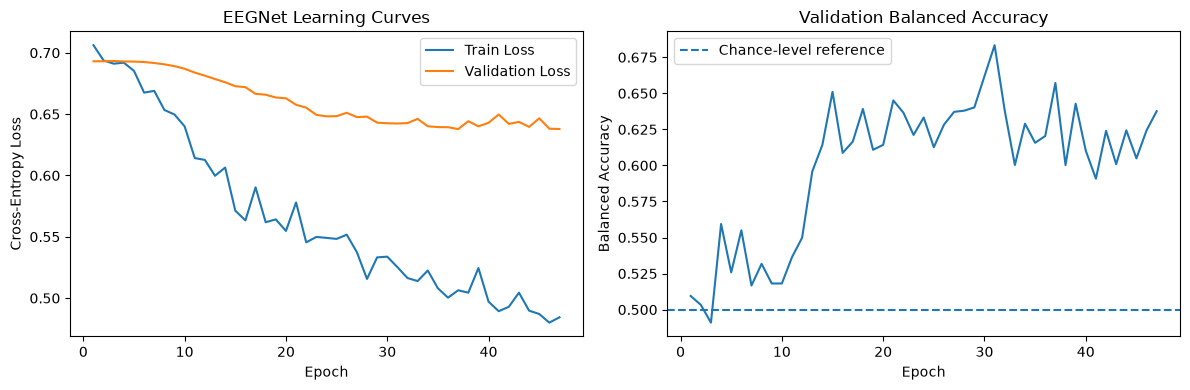

,Subject,BA,Macro-F1,Predicted T1,Predicted T2
0,S004,0.652,0.600,7,38
1,S008,0.711,0.711,23,22
2,S012,0.726,0.727,17,28
3,S016,0.714,0.706,29,16
4,S020,0.487,0.485,26,19


Mean subject BA: 0.658
Pooled validation BA: 0.657
Restored best epoch: 37


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["Epoch"], history_df["Train Loss"], label="Train Loss")
axes[0].plot(history_df["Epoch"], history_df["Val Loss"], label="Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("EEGNet Learning Curves")
axes[0].legend()

axes[1].plot(history_df["Epoch"], history_df["Val BA"])
axes[1].axhline(0.5, linestyle="--", label="Chance-level reference")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Balanced Accuracy")
axes[1].set_title("Validation Balanced Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

eegnet_model.eval()

with torch.no_grad():
    val_predictions = eegnet_model(torch.from_numpy(X_eegnet[val_idx])).argmax(dim=1).cpu().numpy()

subject_results = []

for subject in np.unique(groups[val_idx]):
    mask = groups[val_idx] == subject

    subject_results.append({"Subject": subject,
                            "BA": balanced_accuracy_score(y[val_idx][mask], val_predictions[mask]),
                            "Macro-F1": f1_score(y[val_idx][mask], val_predictions[mask], average="macro"),
                            "Predicted T1": int(np.sum(val_predictions[mask] == 0)),
                            "Predicted T2": int(np.sum(val_predictions[mask] == 1))})

eegnet_subject_df = pd.DataFrame(subject_results)

display(eegnet_subject_df.round(3))
print("Mean subject BA:", round(eegnet_subject_df["BA"].mean(), 3))
print("Pooled validation BA:", round(balanced_accuracy_score(y[val_idx], val_predictions), 3))
print("Restored best epoch:", best_epoch)

**Conclusion:** EEGNet achieved a mean validation BA of 0.658 across five subjects. Training loss decreased steadily, while validation loss reached its minimum at epoch 37, suggesting emerging overfitting. Performance varied across subjects (BA: 0.487–0.726), highlighting the challenges of cross-subject generalization.

### 5.4 EEGNet: Full LOSO Evaluation

We evaluate the fixed six-channel EEGNet across all 20 subjects using LOSO cross-validation.

Each fold trains a new model with subject-independent validation for early stopping. Balanced Accuracy and Macro-F1 are reported for each held-out subject.

This previously completed evaluation is retained as an exploratory baseline rather than an independent test of the selected configuration.

In [25]:
eegnet_loso_results = []

for fold, (train_val_idx, test_idx) in enumerate(outer_cv.split(X_eegnet, y, groups), start=1):
    inner_train, inner_val = next(inner_cv.split(X_eegnet[train_val_idx], 
                                                 y[train_val_idx], groups[train_val_idx]))

    train_idx = train_val_idx[inner_train]
    val_idx = train_val_idx[inner_val]

    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
    assert set(groups[test_idx]).isdisjoint(set(groups[train_idx]))
    assert set(groups[test_idx]).isdisjoint(set(groups[val_idx]))

    model, fold_history, best_epoch, best_loss = training.train_model(X_eegnet[train_idx], y[train_idx], 
                                                                      X_eegnet[val_idx], y[val_idx], architecture="EEGNet")

    model.eval()
    with torch.no_grad():
        y_pred = model(torch.from_numpy(X_eegnet[test_idx])).argmax(dim=1).cpu().numpy()

    subject = groups[test_idx][0]
    ba = balanced_accuracy_score(y[test_idx], y_pred)
    macro_f1 = f1_score(y[test_idx], y_pred, average="macro")

    eegnet_loso_results.append({"Subject": subject, "BA": ba,
                                "Macro-F1": macro_f1, "Best Epoch": best_epoch,
                                "Best Val Loss": best_loss,
                                "Predicted T1": int(np.sum(y_pred == 0)),
                                "Predicted T2": int(np.sum(y_pred == 1))})

    print(f"Fold {fold:02d}/20 | {subject} | BA: {ba:.3f} | F1: {macro_f1:.3f} | Best epoch: {best_epoch}")

eegnet_loso_df = pd.DataFrame(eegnet_loso_results)

display(eegnet_loso_df.round(3))

print("\nMean LOSO BA:", round(eegnet_loso_df["BA"].mean(), 3))
print("Mean LOSO Macro-F1:", round(eegnet_loso_df["Macro-F1"].mean(), 3))
print("Std LOSO BA:", round(eegnet_loso_df["BA"].std(), 3))
print("Completed folds:", len(eegnet_loso_df))

Fold 01/20 | S001 | BA: 0.732 | F1: 0.732 | Best epoch: 37
Fold 02/20 | S002 | BA: 0.614 | F1: 0.550 | Best epoch: 57
Fold 03/20 | S003 | BA: 0.483 | F1: 0.450 | Best epoch: 44
Fold 04/20 | S004 | BA: 0.564 | F1: 0.482 | Best epoch: 36
Fold 05/20 | S005 | BA: 0.542 | F1: 0.527 | Best epoch: 32
Fold 06/20 | S006 | BA: 0.554 | F1: 0.498 | Best epoch: 31
Fold 07/20 | S007 | BA: 1.000 | F1: 1.000 | Best epoch: 35
Fold 08/20 | S008 | BA: 0.668 | F1: 0.666 | Best epoch: 35
Fold 09/20 | S009 | BA: 0.491 | F1: 0.489 | Best epoch: 36
Fold 10/20 | S010 | BA: 0.554 | F1: 0.554 | Best epoch: 43
Fold 11/20 | S011 | BA: 0.546 | F1: 0.459 | Best epoch: 50
Fold 12/20 | S012 | BA: 0.732 | F1: 0.732 | Best epoch: 50
Fold 13/20 | S013 | BA: 0.601 | F1: 0.600 | Best epoch: 31
Fold 14/20 | S014 | BA: 0.577 | F1: 0.577 | Best epoch: 26
Fold 15/20 | S015 | BA: 0.672 | F1: 0.649 | Best epoch: 31
Fold 16/20 | S016 | BA: 0.625 | F1: 0.615 | Best epoch: 30
Fold 17/20 | S017 | BA: 0.500 | F1: 0.338 | Best epoch: 

,Subject,BA,Macro-F1,Best Epoch,Best Val Loss,Predicted T1,Predicted T2
0,S001,0.732,0.732,37,0.638,25,20
1,S002,0.614,0.550,57,0.621,40,5
2,S003,0.483,0.450,44,0.626,34,11
3,S004,0.564,0.482,36,0.662,5,40
4,S005,0.542,0.527,32,0.665,13,32
5,S006,0.554,0.498,31,0.667,9,36
6,S007,1.000,1.000,35,0.671,23,22
7,S008,0.668,0.666,35,0.598,25,20
8,S009,0.491,0.489,36,0.608,21,24
9,S010,0.554,0.554,43,0.596,24,21



Mean LOSO BA: 0.607
Mean LOSO Macro-F1: 0.576
Std LOSO BA: 0.134
Completed folds: 20


**Conclusion:** EEGNet achieved a mean LOSO balanced accuracy of 0.607 and Macro-F1 of 0.576 across 20 subjects. Performance varied substantially (BA: 0.383–1.000), including occasional single-class prediction collapse. The results highlight the challenges of subject-independent EEG classification.

## 6. DeepConvNet

### 6.1 Architecture Validation

DeepConvNet (`Deep4Net`) uses a deeper convolutional architecture than EEGNet.

We validate the model using six EEG channels and both temporal windows (0–2 s and 0–4 s).

Braindecode may adapt the architecture for shorter inputs. We examine model compatibility and trainable parameters before evaluating channel configurations.

**Reference:** [Schirrmeister et al. (2017)](https://doi.org/10.1002/hbm.23730).

In [26]:
from braindecode.models import Deep4Net

deepconv_architecture_results = []

for window_name in ["0–2 s", "0–4 s"]:
    X_data = eegnet_configs[("6 channels", window_name)]

    torch.manual_seed(42)
    model = Deep4Net(n_chans=X_data.shape[1], n_outputs=2, n_times=X_data.shape[-1], sfreq=160)

    model.eval()

    with torch.no_grad():
        output = model(torch.from_numpy(X_data[:8]))

    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

    deepconv_architecture_results.append({"Window": window_name,
                                          "Input shape": str(X_data.shape),
                                          "Output shape": str(tuple(output.shape)),
                                          "Parameters": parameters})

    assert output.shape == (8, 2)
    assert torch.isfinite(output).all()

display(pd.DataFrame(deepconv_architecture_results))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(


,Window,Input shape,Output shape,Parameters
0,0–2 s,"(900, 6, 321)","(8, 2)",194127
1,0–4 s,"(900, 6, 641)","(8, 2)",268477


**Conclusion:** Deep4Net successfully processed both temporal windows. The 0–2 s configuration required automatic architectural adaptation and contained 194,127 trainable parameters, compared with 268,477 for 0–4 s. Consequently, temporal comparisons also reflect differences in effective model architecture.

### 6.2 DeepConvNet: Channel and Temporal Sensitivity

Both temporal configurations passed architecture validation.

We evaluate four channel sets and two temporal windows using identical subject-aware splits, with separate training, early stopping, and configuration-scoring subjects.

Balanced Accuracy is the primary selection metric; Macro-F1 and training convergence are also examined.

In [27]:
deepconv_sensitivity_results = []

for (channel_name, window_name), X_data in eegnet_configs.items():
    results_df = evaluation.evaluate_deep_config(
        X_data, y, groups, outer_train_idx, architecture="Deep4Net", max_folds=4)

    deepconv_sensitivity_results.append({"Channels": channel_name,
                                         "Window": window_name,
                                         "Mean BA": results_df["BA"].mean(),
                                         "Std BA": results_df["BA"].std(),
                                         "Macro-F1": results_df["Macro-F1"].mean(),
                                         "Mean Best Epoch": results_df.groupby("Fold")["Best Epoch"].first().mean()})

    print(f"{channel_name}, {window_name} | BA: {results_df['BA'].mean():.3f} | F1: {results_df['Macro-F1'].mean():.3f}")

deepconv_sensitivity_df = pd.DataFrame(deepconv_sensitivity_results)

display(deepconv_sensitivity_df.round(3))

deepconv_pivot = deepconv_sensitivity_df.pivot(index="Channels", columns="Window", values="Mean BA")
deepconv_pivot["Difference (4s - 2s)"] = deepconv_pivot["0–4 s"] - deepconv_pivot["0–2 s"]

display(deepconv_pivot.round(3))

print("Evaluated configurations:", len(deepconv_sensitivity_df))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling,

3 channels, 0–2 s | BA: 0.530 | F1: 0.497


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling,

5 channels, 0–2 s | BA: 0.487 | F1: 0.442


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling,

6 channels, 0–2 s | BA: 0.553 | F1: 0.533


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling,

15 channels, 0–2 s | BA: 0.517 | F1: 0.454
3 channels, 0–4 s | BA: 0.507 | F1: 0.469
5 channels, 0–4 s | BA: 0.494 | F1: 0.459
6 channels, 0–4 s | BA: 0.529 | F1: 0.460
15 channels, 0–4 s | BA: 0.510 | F1: 0.422


,Channels,Window,Mean BA,Std BA,Macro-F1,Mean Best Epoch
0,3 channels,0–2 s,0.530,0.047,0.497,15.25
1,5 channels,0–2 s,0.487,0.069,0.442,13.25
2,6 channels,0–2 s,0.553,0.083,0.533,13.25
3,15 channels,0–2 s,0.517,0.057,0.454,14.25
4,3 channels,0–4 s,0.507,0.049,0.469,13.75
5,5 channels,0–4 s,0.494,0.062,0.459,23.75
6,6 channels,0–4 s,0.529,0.080,0.460,17.75
7,15 channels,0–4 s,0.510,0.067,0.422,16.25


Window,0–2 s,0–4 s,Difference (4s - 2s)
Channels,,,
15 channels,0.517,0.510,-0.007
3 channels,0.530,0.507,-0.023
5 channels,0.487,0.494,0.007
6 channels,0.553,0.529,-0.024


Evaluated configurations: 8


**Conclusion:** Six channels with a 0–2 s window achieved the highest DeepConvNet balanced accuracy (0.553) and Macro-F1 (0.533). Shorter windows performed better in three of four channel configurations. However, the differences were modest, and automatic architectural adaptation limits direct temporal comparisons. The six-channel, 0–2 s configuration is retained as the primary DeepConvNet candidate.

### 6.3 DeepConvNet: Training Diagnostics

The six-channel, 0–2 s configuration achieved the highest mean BA in the sensitivity analysis.

We examine training and validation loss using a subject-aware split, with S001 excluded from training and early stopping.

Learning curves are used to assess convergence and potential overfitting before reviewing the previously completed full LOSO baseline.

In [28]:
deep_X = eegnet_configs[("6 channels", "0–2 s")]

deep_outer_train, deep_outer_test = next(outer_cv.split(deep_X, y, groups))
deep_inner_train, deep_inner_val = next(inner_cv.split(
    deep_X[deep_outer_train], y[deep_outer_train], groups[deep_outer_train]))

deep_train_idx = deep_outer_train[deep_inner_train]
deep_val_idx = deep_outer_train[deep_inner_val]

deepconv_model, deepconv_history, deepconv_best_epoch, deepconv_best_loss = training.train_model(
    deep_X[deep_train_idx], y[deep_train_idx], deep_X[deep_val_idx], y[deep_val_idx],architecture="Deep4Net")

deepconv_history_df = pd.DataFrame(deepconv_history)

print("Training epochs:", len(deepconv_history_df))
print("Best epoch:", deepconv_best_epoch)
print("Best validation loss:", round(deepconv_best_loss, 4))
print("Training subjects:", len(np.unique(groups[deep_train_idx])))
print("Validation subjects:", len(np.unique(groups[deep_val_idx])))
print("Excluded test subject:", np.unique(groups[deep_outer_test]))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(


Training epochs: 13
Best epoch: 3
Best validation loss: 0.6892
Training subjects: 14
Validation subjects: 5
Excluded test subject: ['S001']


**Conclusion:** DeepConvNet stopped after 13 epochs, selecting epoch 3 with a validation loss of 0.6892. Compared with EEGNet, training converged less effectively on this split. Learning curves and subject-level validation metrics are examined next.

#### Learning Curves and Subject-Level Validation

We examine training and validation loss to understand why early stopping selected epoch 3.

The restored checkpoint is also evaluated separately for each validation subject to assess classification performance and prediction balance.

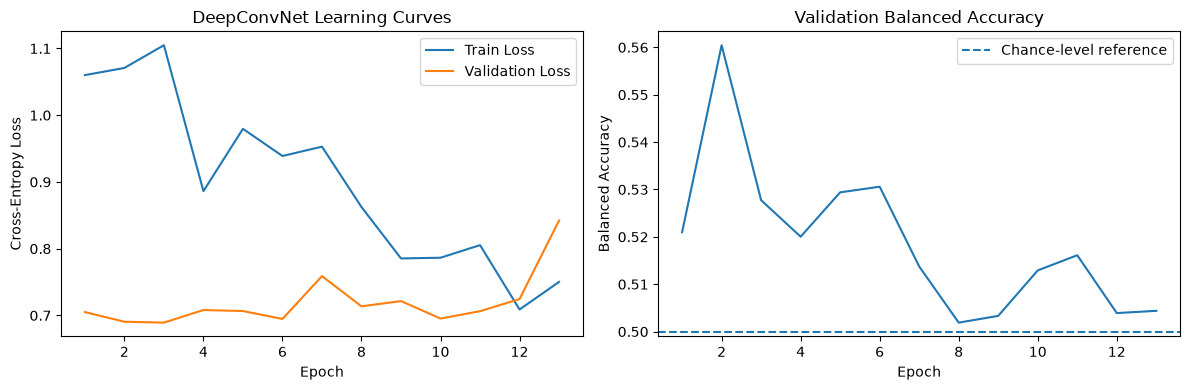

,Subject,BA,Macro-F1,Predicted T1,Predicted T2
0,S004,0.551,0.537,31,14
1,S008,0.558,0.550,28,17
2,S012,0.464,0.402,36,9
3,S016,0.558,0.550,28,17
4,S020,0.500,0.338,45,0


Mean subject BA: 0.526
Pooled validation BA: 0.528
Restored best epoch: 3


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(deepconv_history_df["Epoch"], deepconv_history_df["Train Loss"], label="Train Loss")
axes[0].plot(deepconv_history_df["Epoch"], deepconv_history_df["Val Loss"], label="Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("DeepConvNet Learning Curves")
axes[0].legend()

axes[1].plot(deepconv_history_df["Epoch"], deepconv_history_df["Val BA"])
axes[1].axhline(0.5, linestyle="--", label="Chance-level reference")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Balanced Accuracy")
axes[1].set_title("Validation Balanced Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

deepconv_model.eval()

with torch.no_grad():
    val_predictions = deepconv_model(torch.from_numpy(deep_X[deep_val_idx])).argmax(dim=1).cpu().numpy()

subject_results = []

for subject in np.unique(groups[deep_val_idx]):
    mask = groups[deep_val_idx] == subject

    subject_results.append({"Subject": subject,
                            "BA": balanced_accuracy_score(y[deep_val_idx][mask], val_predictions[mask]),
                            "Macro-F1": f1_score(y[deep_val_idx][mask], val_predictions[mask], average="macro"),
                            "Predicted T1": int(np.sum(val_predictions[mask] == 0)),
                            "Predicted T2": int(np.sum(val_predictions[mask] == 1))})

deepconv_subject_df = pd.DataFrame(subject_results)

display(deepconv_subject_df.round(3))

print("Mean subject BA:", round(deepconv_subject_df["BA"].mean(), 3))
print("Pooled validation BA:", round(balanced_accuracy_score(y[deep_val_idx], val_predictions), 3))
print("Restored best epoch:", deepconv_best_epoch)

**Conclusion:** DeepConvNet achieved a mean validation BA of 0.526 across five subjects. Validation loss did not improve after epoch 3, and classification performance remained close to chance level. Single-class prediction collapse was observed for S020, indicating limited cross-subject generalization on this split.

### 6.4 DeepConvNet: Full LOSO Evaluation

We evaluate the fixed six-channel DeepConvNet using Leave-One-Subject-Out cross-validation across 20 subjects.

Each fold trains a new model with subject-independent validation for early stopping. Balanced Accuracy and Macro-F1 are calculated for each held-out subject.

This previously completed experiment is retained as an exploratory baseline rather than an independent evaluation of the selected configuration.

In [30]:
deepconv_loso_results = []

for fold, (train_val_idx, test_idx) in enumerate(outer_cv.split(X_eegnet, y, groups), start=1):
    inner_train, inner_val = next(inner_cv.split(
        X_eegnet[train_val_idx], y[train_val_idx], groups[train_val_idx]))

    train_idx = train_val_idx[inner_train]
    val_idx = train_val_idx[inner_val]

    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
    assert set(groups[test_idx]).isdisjoint(set(groups[train_idx]))
    assert set(groups[test_idx]).isdisjoint(set(groups[val_idx]))

    model, fold_history, best_epoch, best_loss = training.train_model(
        X_eegnet[train_idx], y[train_idx],
        X_eegnet[val_idx], y[val_idx], architecture="Deep4Net")

    model.eval()
    with torch.no_grad():
        y_pred = model(torch.from_numpy(X_eegnet[test_idx])).argmax(dim=1).cpu().numpy()

    subject = groups[test_idx][0]
    ba = balanced_accuracy_score(y[test_idx], y_pred)
    macro_f1 = f1_score(y[test_idx], y_pred, average="macro")

    deepconv_loso_results.append({"Subject": subject, "BA": ba,
                                  "Macro-F1": macro_f1, "Best Epoch": best_epoch,
                                  "Best Val Loss": best_loss,
                                  "Predicted T1": int(np.sum(y_pred == 0)),
                                  "Predicted T2": int(np.sum(y_pred == 1))})

    print(f"Fold {fold:02d}/20 | {subject} | BA: {ba:.3f} | F1: {macro_f1:.3f} | Best epoch: {best_epoch}")

deepconv_loso_df = pd.DataFrame(deepconv_loso_results)

display(deepconv_loso_df.round(3))

print("\nMean LOSO BA:", round(deepconv_loso_df["BA"].mean(), 3))
print("Mean LOSO Macro-F1:", round(deepconv_loso_df["Macro-F1"].mean(), 3))
print("Std LOSO BA:", round(deepconv_loso_df["BA"].std(), 3))
print("Completed folds:", len(deepconv_loso_df))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(


Fold 01/20 | S001 | BA: 0.625 | F1: 0.619 | Best epoch: 3


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(


Fold 02/20 | S002 | BA: 0.706 | F1: 0.689 | Best epoch: 15


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(


Fold 03/20 | S003 | BA: 0.511 | F1: 0.511 | Best epoch: 24


... (32 outputs left out)

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/deep4.py:167: UserWarning: n_times (321) is smaller than the minimum required (441) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.73
  warn(


Fold 20/20 | S020 | BA: 0.502 | F1: 0.405 | Best epoch: 30


,Subject,BA,Macro-F1,Best Epoch,Best Val Loss,Predicted T1,Predicted T2
0,S001,0.625,0.619,3,0.689,18,27
1,S002,0.706,0.689,15,0.687,34,11
2,S003,0.511,0.511,24,0.663,23,22
3,S004,0.649,0.630,12,0.695,13,32
4,S005,0.542,0.530,12,0.694,28,17
5,S006,0.560,0.555,12,0.698,20,25
6,S007,0.602,0.598,9,0.700,19,26
7,S008,0.622,0.621,9,0.690,21,24
8,S009,0.557,0.555,12,0.685,22,23
9,S010,0.524,0.518,11,0.672,29,16



Mean LOSO BA: 0.575
Mean LOSO Macro-F1: 0.555
Std LOSO BA: 0.071
Completed folds: 20


**Conclusion:** DeepConvNet achieved a mean LOSO balanced accuracy of 0.575 and Macro-F1 of 0.555 across 20 subjects. Performance varied across participants, and the model did not consistently generalize to unseen subjects. The fixed six-channel, 0–2 s configuration is retained as an exploratory baseline.

## 7. ATCNet

### 7.1 Architecture Validation

ATCNet combines convolutional feature extraction, attention, and temporal convolutional networks.

We validate the architecture using six EEG channels and two temporal windows (0–2 s and 0–4 s).

Since Braindecode may adapt the model for shorter inputs, we compare input compatibility and trainable parameters before evaluating different channel configurations.

**Reference:** [Altaheri et al. (2022)](https://doi.org/10.1109/TII.2022.3197419).

In [31]:
from braindecode.models import ATCNet

atcnet_architecture_results = []

for window_name in ["0–2 s", "0–4 s"]:
    X_data = eegnet_configs[("6 channels", window_name)]

    torch.manual_seed(42)
    model = ATCNet(n_chans=X_data.shape[1], n_outputs=2, n_times=X_data.shape[-1], sfreq=160)
    model.eval()

    with torch.no_grad():
        output = model(torch.from_numpy(X_data[:8]))

    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    atcnet_architecture_results.append({"Window": window_name,
                                        "Input shape": str(X_data.shape),
                                        "Output shape": str(tuple(output.shape)),
                                        "Parameters": parameters})
    assert output.shape == (8, 2)
    assert torch.isfinite(output).all()

display(pd.DataFrame(atcnet_architecture_results))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(


,Window,Input shape,Output shape,Parameters
0,0–2 s,"(900, 6, 321)","(8, 2)",30740
1,0–4 s,"(900, 6, 641)","(8, 2)",112890


**Conclusion:** ATCNet successfully processed both temporal windows. The 0–2 s configuration required automatic architectural adaptation and contained 30,740 trainable parameters, compared with 112,890 for 0–4 s. Temporal comparisons therefore reflect changes in both input duration and effective model architecture.

### 7.2 ATCNet: Channel and Temporal Sensitivity

We evaluate four channel configurations and two temporal windows using the same subject-aware protocol as EEGNet and DeepConvNet.

Balanced Accuracy is the primary selection metric, with Macro-F1 and training convergence examined as secondary measures.

In [32]:
atcnet_sensitivity_results = []

for (channel_name, window_name), X_data in eegnet_configs.items():
    results_df = evaluation.evaluate_deep_config(X_data, y, groups, outer_train_idx, architecture="ATCNet", max_folds=4)

    atcnet_sensitivity_results.append({
        "Channels": channel_name,
        "Window": window_name,
        "Mean BA": results_df["BA"].mean(),
        "Std BA": results_df["BA"].std(),
        "Macro-F1": results_df["Macro-F1"].mean(),
        "Mean Best Epoch": results_df.groupby("Fold")["Best Epoch"].first().mean()})

    print(f"{channel_name}, {window_name} | BA: {results_df['BA'].mean():.3f} | F1: {results_df['Macro-F1'].mean():.3f}")

atcnet_sensitivity_df = pd.DataFrame(atcnet_sensitivity_results)
display(atcnet_sensitivity_df.round(3))

atcnet_pivot = atcnet_sensitivity_df.pivot(
    index="Channels", columns="Window", values="Mean BA")

atcnet_pivot["Difference (4s - 2s)"] = atcnet_pivot["0–4 s"] - atcnet_pivot["0–2 s"]

display(atcnet_pivot.round(3))

print("Evaluated configurations:", len(atcnet_sensitivity_df))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooli

3 channels, 0–2 s | BA: 0.514 | F1: 0.483


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooli

5 channels, 0–2 s | BA: 0.517 | F1: 0.486


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooli

6 channels, 0–2 s | BA: 0.519 | F1: 0.487


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(
/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooli

15 channels, 0–2 s | BA: 0.497 | F1: 0.473
3 channels, 0–4 s | BA: 0.531 | F1: 0.433
5 channels, 0–4 s | BA: 0.526 | F1: 0.479
6 channels, 0–4 s | BA: 0.577 | F1: 0.538
15 channels, 0–4 s | BA: 0.518 | F1: 0.454


,Channels,Window,Mean BA,Std BA,Macro-F1,Mean Best Epoch
0,3 channels,0–2 s,0.514,0.061,0.483,7.25
1,5 channels,0–2 s,0.517,0.080,0.486,4.75
2,6 channels,0–2 s,0.519,0.076,0.487,5.25
3,15 channels,0–2 s,0.497,0.071,0.473,3.50
4,3 channels,0–4 s,0.531,0.073,0.433,11.25
5,5 channels,0–4 s,0.526,0.070,0.479,12.75
6,6 channels,0–4 s,0.577,0.111,0.538,15.75
7,15 channels,0–4 s,0.518,0.066,0.454,9.50


Window,0–2 s,0–4 s,Difference (4s - 2s)
Channels,,,
15 channels,0.497,0.518,0.022
3 channels,0.514,0.531,0.017
5 channels,0.517,0.526,0.009
6 channels,0.519,0.577,0.058


Evaluated configurations: 8


**Conclusion:** ATCNet achieved its highest balanced accuracy (0.577) and Macro-F1 (0.538) using six channels and a 0–4 s window. Longer windows improved BA across all channel configurations, with the largest gain observed for six channels (+0.058). However, performance variability and differences in model architecture limit definitive conclusions. The six-channel, 0–4 s configuration is selected for further diagnostic analysis.

### 7.3 ATCNet: Training Diagnostics

The six-channel, 0–4 s configuration achieved the highest balanced accuracy in the sensitivity analysis.

We examine training and validation loss using a subject-aware split to assess convergence, early stopping, and potential overfitting.

In [33]:
atcnet_X = eegnet_configs[("6 channels", "0–4 s")]

atcnet_outer_train, atcnet_outer_test = next(outer_cv.split(atcnet_X, y, groups))

atcnet_inner_train, atcnet_inner_val = next(inner_cv.split(atcnet_X[atcnet_outer_train], y[atcnet_outer_train],
                                                           groups[atcnet_outer_train]))

atcnet_train_idx = atcnet_outer_train[atcnet_inner_train]
atcnet_val_idx = atcnet_outer_train[atcnet_inner_val]

atcnet_model, atcnet_history, atcnet_best_epoch, atcnet_best_loss = training.train_model(
    atcnet_X[atcnet_train_idx], y[atcnet_train_idx], atcnet_X[atcnet_val_idx], y[atcnet_val_idx], architecture="ATCNet")

atcnet_history_df = pd.DataFrame(atcnet_history)

print("Training epochs:", len(atcnet_history_df))
print("Best epoch:", atcnet_best_epoch)
print("Best validation loss:", round(atcnet_best_loss, 4))
print("Training subjects:", len(np.unique(groups[atcnet_train_idx])))
print("Validation subjects:", len(np.unique(groups[atcnet_val_idx])))
print("Excluded test subject:", np.unique(groups[atcnet_outer_test]))

Training epochs: 33
Best epoch: 23
Best validation loss: 0.66
Training subjects: 14
Validation subjects: 5
Excluded test subject: ['S001']


**Conclusion:** ATCNet reached its minimum validation loss (0.660) at epoch 23 and stopped after 33 epochs. This indicates continued validation improvement beyond the early training stages, although classification performance requires further examination.

#### Learning Curves

ATCNet reached its minimum validation loss at epoch 23, with early stopping at epoch 33.

We examine training loss, validation loss, and validation balanced accuracy to assess convergence and potential overfitting.

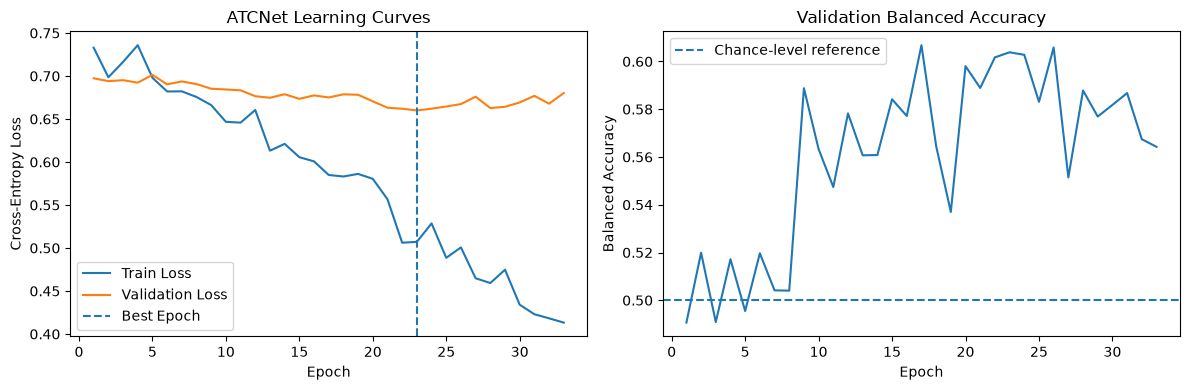

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(atcnet_history_df["Epoch"], atcnet_history_df["Train Loss"], label="Train Loss")
axes[0].plot(atcnet_history_df["Epoch"], atcnet_history_df["Val Loss"], label="Validation Loss")
axes[0].axvline(atcnet_best_epoch, linestyle="--", label="Best Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("ATCNet Learning Curves")
axes[0].legend()

axes[1].plot(atcnet_history_df["Epoch"], atcnet_history_df["Val BA"])
axes[1].axhline(0.5, linestyle="--", label="Chance-level reference")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Balanced Accuracy")
axes[1].set_title("Validation Balanced Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

**Conclusion:** Training loss decreased steadily, while validation loss reached its minimum at epoch 23 and subsequently increased, indicating overfitting. Validation BA fluctuated around 0.55–0.61 during later epochs, suggesting modest and unstable cross-subject generalization.

#### Subject-Level Validation

We evaluate the best ATCNet checkpoint separately for each validation subject.

Balanced Accuracy, Macro-F1, and predicted class counts are examined to identify subject-specific performance differences and possible single-class prediction collapse.

In [35]:
atcnet_model.eval()

with torch.no_grad():
    atcnet_val_pred = atcnet_model(torch.from_numpy(atcnet_X[atcnet_val_idx])).argmax(dim=1).cpu().numpy()

atcnet_subject_results = []

for subject in np.unique(groups[atcnet_val_idx]):
    mask = groups[atcnet_val_idx] == subject

    atcnet_subject_results.append({
        "Subject": subject,
        "BA": balanced_accuracy_score(y[atcnet_val_idx][mask], atcnet_val_pred[mask]),
        "Macro-F1": f1_score(y[atcnet_val_idx][mask], atcnet_val_pred[mask], average="macro"),
        "Predicted T1": int(np.sum(atcnet_val_pred[mask] == 0)),
        "Predicted T2": int(np.sum(atcnet_val_pred[mask] == 1))})

atcnet_subject_df = pd.DataFrame(atcnet_subject_results)

display(atcnet_subject_df.round(3))

print("Mean subject BA:", round(atcnet_subject_df["BA"].mean(), 3))
print("Pooled validation BA:", round(balanced_accuracy_score(
    y[atcnet_val_idx], atcnet_val_pred), 3))
print("Restored best epoch:", atcnet_best_epoch)

,Subject,BA,Macro-F1,Predicted T1,Predicted T2
0,S004,0.642,0.640,27,18
1,S008,0.696,0.661,36,9
2,S012,0.598,0.545,36,9
3,S016,0.540,0.498,35,10
4,S020,0.545,0.432,43,2


Mean subject BA: 0.604
Pooled validation BA: 0.604
Restored best epoch: 23


**Conclusion:** ATCNet achieved a mean validation BA of 0.604 across five subjects, with the highest performance observed for S008 (0.696). Both classes were predicted for every subject, although a strong T1 prediction bias remained, particularly for S020. These validation results are diagnostic and do not represent independent test performance.

### 7.4 ATCNet: Full LOSO Evaluation

We report the previously completed 20-subject LOSO evaluation using the fixed six-channel, 0–2 s ATCNet configuration.

Each fold uses subject-independent validation for early stopping. Balanced Accuracy and Macro-F1 are calculated for each held-out subject.

These results serve as an exploratory baseline.

In [36]:
atcnet_loso_results = []

for fold, (train_val_idx, test_idx) in enumerate(outer_cv.split(X_eegnet, y, groups), start=1):
    inner_train, inner_val = next(inner_cv.split(X_eegnet[train_val_idx], y[train_val_idx], groups[train_val_idx]))

    train_idx = train_val_idx[inner_train]
    val_idx = train_val_idx[inner_val]

    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
    assert set(groups[test_idx]).isdisjoint(set(groups[train_idx]))
    assert set(groups[test_idx]).isdisjoint(set(groups[val_idx]))

    model, fold_history, best_epoch, best_loss = training.train_model(
        X_eegnet[train_idx], y[train_idx], X_eegnet[val_idx], y[val_idx], architecture="ATCNet")

    model.eval()
    with torch.no_grad():
        y_pred = model(torch.from_numpy(X_eegnet[test_idx])).argmax(dim=1).cpu().numpy()

    subject = groups[test_idx][0]
    ba = balanced_accuracy_score(y[test_idx], y_pred)
    macro_f1 = f1_score(y[test_idx], y_pred, average="macro")

    atcnet_loso_results.append({"Subject": subject, "BA": ba,
                                "Macro-F1": macro_f1, "Best Epoch": best_epoch,
                                "Best Val Loss": best_loss,
                                "Predicted T1": int(np.sum(y_pred == 0)),
                                "Predicted T2": int(np.sum(y_pred == 1))})

    print(f"Fold {fold:02d}/20 | {subject} | BA: {ba:.3f} | F1: {macro_f1:.3f} | Best epoch: {best_epoch}")

atcnet_loso_df = pd.DataFrame(atcnet_loso_results)

display(atcnet_loso_df.round(3))

print("\nMean LOSO BA:", round(atcnet_loso_df["BA"].mean(), 3))
print("Mean LOSO Macro-F1:", round(atcnet_loso_df["Macro-F1"].mean(), 3))
print("Std LOSO BA:", round(atcnet_loso_df["BA"].std(), 3))
print("Completed folds:", len(atcnet_loso_df))

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(


Fold 01/20 | S001 | BA: 0.557 | F1: 0.554 | Best epoch: 29


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(


Fold 02/20 | S002 | BA: 0.553 | F1: 0.550 | Best epoch: 1


/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(


Fold 03/20 | S003 | BA: 0.467 | F1: 0.466 | Best epoch: 39


... (32 outputs left out)

/Users/LOCAL_USER/anaconda3/envs/eeg_ml/lib/python3.11/site-packages/braindecode/models/atcnet.py:302: UserWarning: n_times (321) is smaller than the minimum required (616) for the current model parameters configuration. Adjusting parameters to ensure compatibility.Reducing the kernel, pooling, and stride sizes accordingly.Scaling factor: 0.52
  warn(


Fold 20/20 | S020 | BA: 0.496 | F1: 0.434 | Best epoch: 6


,Subject,BA,Macro-F1,Best Epoch,Best Val Loss,Predicted T1,Predicted T2
0,S001,0.557,0.554,29,0.665,19,26
1,S002,0.553,0.550,1,0.695,27,18
2,S003,0.467,0.466,39,0.661,21,24
3,S004,0.647,0.640,18,0.687,17,28
4,S005,0.554,0.554,18,0.685,21,24
5,S006,0.494,0.488,1,0.702,19,26
6,S007,0.535,0.532,7,0.695,20,25
7,S008,0.514,0.505,1,0.696,28,17
8,S009,0.527,0.525,1,0.695,27,18
9,S010,0.515,0.511,1,0.698,20,25



Mean LOSO BA: 0.516
Mean LOSO Macro-F1: 0.504
Std LOSO BA: 0.053
Completed folds: 20


**Conclusion:** ATCNet achieved a mean LOSO balanced accuracy of 0.516 and Macro-F1 of 0.504 across 20 subjects, performing near chance level and below the other evaluated models. Seven folds selected epoch 1 as the best checkpoint. The substantial automatic adaptation to the 321-sample input and limited training data may have affected performance. These findings apply to the tested configuration, not ATCNet in general.

## 8. Model Comparison

We compare subject-level LOSO performance across classical and deep learning models using paired balanced accuracy differences and bootstrap confidence intervals.

These comparisons are exploratory, as training procedures and model configurations differ.

### 8.1 EEGNet vs Classical ML

We compare EEGNet with the fixed six-channel CSP + LDA baseline using subject-level balanced accuracy from 20 LOSO folds.

Paired differences and bootstrap confidence intervals are used to assess whether performance differences are consistent across subjects.

The comparison remains exploratory due to differences in training procedures.

In [37]:
eegnet_comparison = eegnet_loso_df[["Subject", "BA"]].rename(columns={"BA": "EEGNet"})
csp_comparison = subject_comparison[["CSP + LDA (6 channels)"]]

comparison = eegnet_comparison.set_index("Subject").join(csp_comparison)
comparison["Difference"] = comparison["EEGNet"] - comparison["CSP + LDA (6 channels)"]

differences = comparison["Difference"].to_numpy()
rng = np.random.default_rng(42)
bootstrap_means = rng.choice(differences, size=(10000, len(differences)), replace=True).mean(axis=1)
ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

display(comparison.round(3))

print("Mean BA difference:", round(differences.mean(), 3))
print("95% bootstrap CI:", (round(ci_lower, 3), round(ci_upper, 3)))
print("EEGNet better:", int((differences > 1e-10).sum()))
print("CSP better:", int((differences < -1e-10).sum()))
print("Equal:", int(np.isclose(differences, 0, atol=1e-10).sum()))

,EEGNet,CSP + LDA (6 channels),Difference
Subject,,,
S001,0.732,0.618,0.115
S002,0.614,0.568,0.045
S003,0.483,0.461,0.022
S004,0.564,0.522,0.042
S005,0.542,0.616,-0.074
S006,0.554,0.458,0.095
S007,1.000,0.889,0.111
S008,0.668,0.715,-0.047
S009,0.491,0.607,-0.116


Mean BA difference: -0.017
95% bootstrap CI: (np.float64(-0.056), np.float64(0.022))
EEGNet better: 7
CSP better: 13
Equal: 0


**Conclusion:** EEGNet achieved a mean BA of 0.607, compared with 0.624 for six-channel CSP + LDA. EEGNet performed better for 7 subjects and worse for 13. The paired mean difference was −0.017 (95% bootstrap CI: [−0.056, 0.022]), providing no conclusive evidence of superiority for either approach. Differences in training procedures and subject-level variability limit direct architectural comparison.

### 8.2 DeepConvNet vs EEGNet

We compare subject-level balanced accuracy between DeepConvNet and EEGNet across the same 20 held-out subjects.

Paired differences and bootstrap confidence intervals are used to examine the consistency of performance differences.

In [38]:
deep_comparison = deepconv_loso_df[["Subject", "BA"]].rename(columns={"BA": "DeepConvNet"})
eegnet_comparison = eegnet_loso_df[["Subject", "BA"]].rename(columns={"BA": "EEGNet"})

comparison = deep_comparison.merge(eegnet_comparison, on="Subject", validate="one_to_one")
comparison["Difference"] = comparison["DeepConvNet"] - comparison["EEGNet"]

differences = comparison["Difference"].to_numpy()

rng = np.random.default_rng(42)
bootstrap_means = rng.choice(differences, size=(10000, len(differences)), replace=True).mean(axis=1)
ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

display(comparison.round(3))

print("Mean BA difference:", round(differences.mean(), 3))
print("95% bootstrap CI:", (round(ci_lower, 3), round(ci_upper, 3)))
print("DeepConvNet better:", int((differences > 1e-10).sum()))
print("EEGNet better:", int((differences < -1e-10).sum()))
print("Equal:", int(np.isclose(differences, 0, atol=1e-10).sum()))

,Subject,DeepConvNet,EEGNet,Difference
0,S001,0.625,0.732,-0.108
1,S002,0.706,0.614,0.092
2,S003,0.511,0.483,0.028
3,S004,0.649,0.564,0.085
4,S005,0.542,0.542,0.000
5,S006,0.560,0.554,0.006
6,S007,0.602,1.000,-0.398
7,S008,0.622,0.668,-0.046
8,S009,0.557,0.491,0.065
9,S010,0.524,0.554,-0.030


Mean BA difference: -0.031
95% bootstrap CI: (np.float64(-0.087), np.float64(0.018))
DeepConvNet better: 7
EEGNet better: 12
Equal: 1


**Conclusion:** DeepConvNet achieved lower mean BA than EEGNet (0.575 vs. 0.607). It outperformed EEGNet for 7 subjects, underperformed for 12, and tied for 1. The paired mean difference was −0.031 (95% bootstrap CI: [−0.087, 0.018]), providing no conclusive evidence of a consistent advantage.

### 8.3 ATCNet vs Other Models

ATCNet achieved the lowest mean LOSO balanced accuracy among the evaluated models.

We compare paired subject-level differences between ATCNet and each baseline, estimating bootstrap confidence intervals to assess the consistency of performance differences.

In [39]:
atc_comparison = atcnet_loso_df[["Subject", "BA"]].rename(columns={"BA": "ATCNet"})
eeg_comparison = eegnet_loso_df[["Subject", "BA"]].rename(columns={"BA": "EEGNet"})
deep_comparison = deepconv_loso_df[["Subject", "BA"]].rename(columns={"BA": "DeepConvNet"})
csp_comparison = subject_comparison[["CSP + LDA (6 channels)"]].reset_index()

comparison = atc_comparison.merge(eeg_comparison, on="Subject", validate="one_to_one")
comparison = comparison.merge(deep_comparison, on="Subject", validate="one_to_one")
comparison = comparison.merge(csp_comparison, on="Subject", validate="one_to_one")

assert len(comparison) == 20

rng = np.random.default_rng(42)
results = []

for baseline in ["CSP + LDA (6 channels)", "EEGNet", "DeepConvNet"]:
    differences = (comparison["ATCNet"] - comparison[baseline]).to_numpy()
    bootstrap_means = rng.choice(differences, size=(10000, len(differences)), replace=True).mean(axis=1)
    ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

    results.append({"Comparison": f"ATCNet - {baseline}",
                    "Mean difference": differences.mean(),
                    "CI lower": ci_lower, "CI upper": ci_upper,
                    "ATCNet better": int((differences > 1e-10).sum()),
                    "Baseline better": int((differences < -1e-10).sum()),
                    "Equal": int(np.isclose(differences, 0, atol=1e-10).sum())})

display(pd.DataFrame(results).round(3))

,Comparison,Mean difference,CI lower,CI upper,ATCNet better,Baseline better,Equal
0,ATCNet - CSP + LDA (6 channels),-0.108,-0.159,-0.059,3,17,0
1,ATCNet - EEGNet,-0.091,-0.150,-0.038,4,16,0
2,ATCNet - DeepConvNet,-0.060,-0.095,-0.029,4,16,0


**Conclusion:** ATCNet (6 channels, 0–2 s) achieved lower LOSO balanced accuracy than CSP + LDA, EEGNet, and DeepConvNet. All three paired bootstrap confidence intervals excluded zero, indicating consistently lower performance for the tested configuration. However, the improved 0–4 s configuration has not undergone full LOSO evaluation, and these comparisons remain exploratory.

## 9. Final Model Selection

### 9.1 Model Performance Summary

We summarize the best configurations identified during subject-aware sensitivity analysis and their corresponding full LOSO results, where available.

Development and LOSO scores are reported separately because they follow different evaluation procedures.

In [42]:
model_summary = pd.DataFrame({
    "Model": ["CSP + LDA", "EEGNet", "DeepConvNet", "ATCNet", "ATCNet (baseline)"],
    "Channels": [6, 6, 6, 6, 6],
    "Window": ["0–2 s", "0–2 s", "0–2 s", "0–4 s", "0–2 s"],
    "Development BA": [0.611, 0.579, 0.553, 0.577, 0.519],
    "Full LOSO BA": [0.624, 0.607, 0.575, np.nan, 0.516]})

display(model_summary.round(3))

,Model,Channels,Window,Development BA,Full LOSO BA
0,CSP + LDA,6,0–2 s,0.611,0.624
1,EEGNet,6,0–2 s,0.579,0.607
2,DeepConvNet,6,0–2 s,0.553,0.575
3,ATCNet,6,0–4 s,0.577,NaN
4,ATCNet (baseline),6,0–2 s,0.519,0.516


**Conclusion:** CSP + LDA achieved the highest development BA (0.611) and full LOSO BA (0.624) among the evaluated configurations. ATCNet showed improvement with a 0–4 s window, but its selected configuration lacks full LOSO evaluation. All results remain exploratory and require independent testing on unseen subjects.

### 9.2 Selected Model

**Primary candidate:** CSP + LDA, 6 channels, 0–2 s.

This configuration achieved the highest development balanced accuracy (0.611) and a fixed-model LOSO BA of 0.624. Its lower complexity and interpretable spatial filters make it a practical choice for independent evaluation.

**Secondary candidate:** ATCNet, 6 channels, 0–4 s (development BA = 0.577). Its generalization remains uncertain because full LOSO evaluation of this configuration has not been completed.

All development results remain exploratory. Final performance must be assessed on previously unseen subjects without further model selection.

### 9.3 Final Evaluation Protocol

The selected CSP + LDA configuration (6 channels, 0–2 s) will be evaluated on previously unseen subjects.

The final evaluation follows these rules:

1. **Fixed configuration:** No further changes to preprocessing, channel selection, feature extraction, or model hyperparameters.
2. **Development data:** Train the final pipeline using the 20 development subjects (S001–S020).
3. **Independent test:** Evaluate on new subjects excluded from all previous experiments.
4. **Metrics:** Report balanced accuracy, Macro-F1, confusion matrices, and subject-level performance.
5. **No test-set tuning:** Test results will not be used to modify the selected model.

The independent evaluation will be conducted in `11_final_evaluation.ipynb`.

## 10. Conclusions and Limitations

### Key Findings

- **CSP + LDA (6 channels, 0–2 s)** achieved the highest fixed-model LOSO balanced accuracy (0.624), followed by EEGNet (0.607), DeepConvNet (0.575), and ATCNet (0.516).
- EEGNet and DeepConvNet performed similarly to their classical counterparts, with paired bootstrap confidence intervals including zero in the relevant comparisons.
- Channel and temporal sensitivity analysis favored six channels and shorter windows for CSP, EEGNet, and DeepConvNet.
- ATCNet performed best with six channels and a 0–4 s window (development BA = 0.577), but this configuration has not undergone full LOSO evaluation.

### Limitations

- The development cohort contained only 20 subjects, with substantial variability in cross-subject performance.
- Model selection and exploratory LOSO evaluation used the same development cohort, so the reported scores are not independent final test estimates.
- Neural architectures required different training procedures, while automatic adaptation changed model capacity across temporal windows.
- Differences between CSP + LDA and EEGNet were not statistically conclusive.

### Final Decision

**CSP + LDA with six channels and a 0–2 s window** was selected as the primary model due to its development performance, simplicity, and interpretability.

The next stage is independent subject-level evaluation in `11_final_evaluation.ipynb`, using previously unseen participants without further model selection.